<a href="https://colab.research.google.com/github/vikrampal12345/Complete-LLM/blob/main/micrograd_from_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install micrograd


In [3]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [4]:
def f(x):
  return 3*x**2 - 4*x + 5

In [5]:
f(3)

20

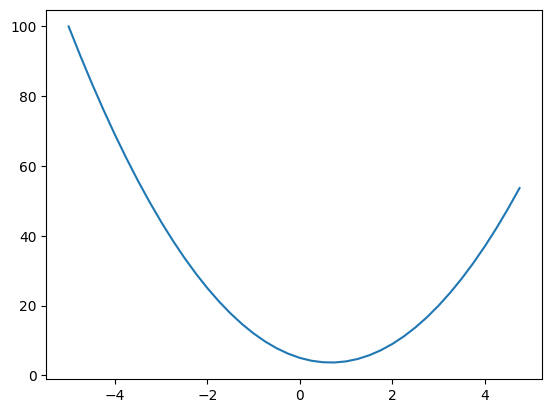

In [6]:

xs = np.arange(-5,5,0.25)
ys = f(xs)
plt.plot(xs, ys)


In [7]:
h = 0.00000001
x = 3
l = (f(xs + h) - f(xs))/h

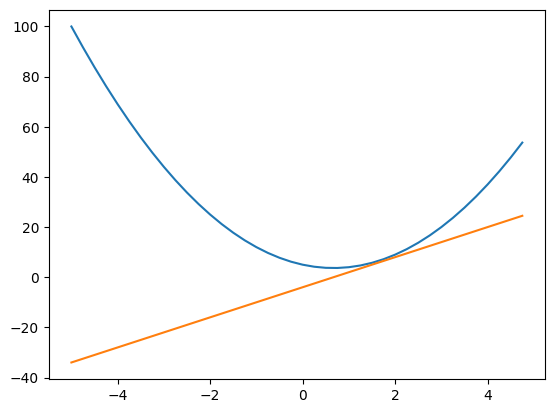

In [8]:
plt.plot(xs, ys)
plt.plot(xs,l)

In [9]:
h = 0.0001

# inputs
a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c
a += h
d2 = a*b + c

print('d1', d1)
print('d2', d2)
print('slope', (d2-d1)/h)

sl = (d2 - d1) / h

d1 4.0
d2 3.999699999999999
slope -3.000000000010772


In [10]:
d1 = a*b + c
c += h
d2 = a*b + c

print('d1', d1)
print('d2', d2)
print('slope', (d2-d1)/h)

d1 3.999699999999999
d2 3.9997999999999987
slope 0.9999999999976694


In [11]:
class Value:

  def __init__(self, data, _children=(), _op='', label = ''):
    self.data = data
    self.grad = 0.0
    self._backward = lambda: None
    self._prev = set(_children)
    self._op = _op
    self.label = label

  def __repr__(self):
    return f"Value(data = {self.data})"

  def __add__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out =  Value(self.data + other.data, (self, other), '+')

    def _backward():
      self.grad += 1.0 * out.grad
      other.grad += 1.0 * out.grad
    out._backward = _backward
    return out

  def __mul__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data * other.data, (self, other), '*')

    def _backward():
      self.grad += other.data * out.grad
      other.grad += self.data * out.grad
    out._backward = _backward

    return out
  def __pow__(self, other):
    assert isinstance(other, (int, float)), "only supporting int/float powers for now"
    out = Value(self.data**other, (self, ), f'**{other}')

    def _backward():
      self.grad += other * (self.data ** (other - 1)) * out.grad
    out._backward = _backward

    return out

  def __rmul__(self, other): # other * self
    return self * other

  def __truediv__(self, other): # self / other
    return self * other**-1

  def __neg__(self): # -self
    return self * -1

  def __sub__(self, other): # self - other
    return self + (-other)


  def tanh(self):
    x = self.data
    t = ((math.exp(2*x) - 1)/ (math.exp(2*x) + 1))
    out = Value(t, (self, ), "tanh")

    def _backward():
      self.grad += (1 - t**2) * out.grad

    out._backward = _backward
    return out

  def exp(self):
    x = self.data
    out = Value(math.exp(x), (self, ), 'exp')

    def _backward():
      self.grad += out.data * out.grad
    out._backward = _backward

    return out

  def backward(self):
    topo = []
    visited = set()

    def build_topo(v):
        if v not in visited:
            visited.add(v)
            for child in v._prev:
                build_topo(child)
            topo.append(v)

    build_topo(self)

    self.grad = 1.0
    for node in reversed(topo):
      node._backward()




In [12]:
a = Value(2.0)
b = Value(4.0)
a/b

Value(data = 0.5)

In [13]:

from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    return nodes, edges


def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})  # LR = left to right

    nodes, edges = trace(root)

    for n in nodes:
        uid = str(id(n))

        # For any value in the graph, create a rectangular ('record') node for it
        dot.node(
            name=uid,
            label="{ %s | data %.4f | grad % .4f }" % (n.label, n.data, n.grad),
            shape='record'
        )

        if n._op:
            # If this value is a result of some operation, create an op node for it
            dot.node(name=uid + n._op, label=n._op)

            # Connect this value node to its operation node
            dot.edge(uid + n._op, uid)

    # Connect parent nodes to operation nodes
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot


In [14]:
# inputs x1, x2

x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights w1, w2

w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

# bias

b = Value(6.8813735870195432, label='b')
x1w1 = x1*w1; x1w1.label = 'x1w1'
x2w2 = x2*w2; x2w2.label = 'x2w2'

x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1x2*w2'
n = x1w1x2w2 + b; n.label = 'n'

o = n.tanh(); o.label = 'o'

o.backward()

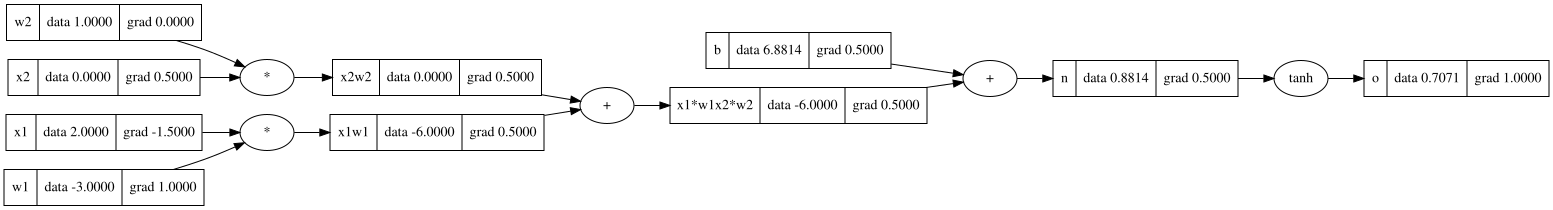

In [15]:
draw_dot(o)

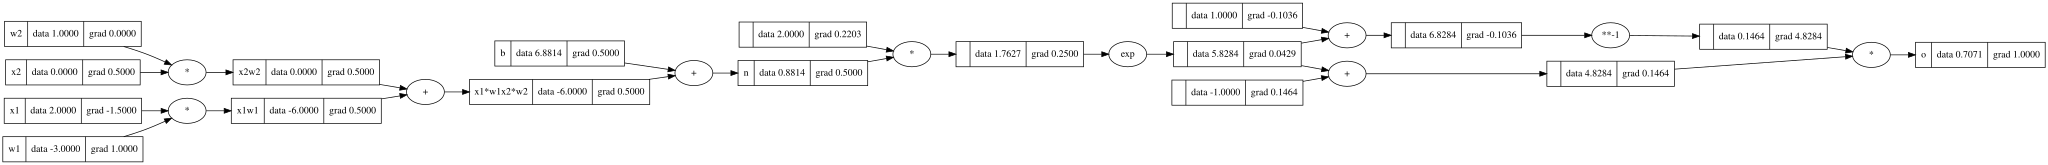

In [16]:
# inputs x1, x2

x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights w1, w2

w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

# bias

b = Value(6.8813735870195432, label='b')
x1w1 = x1*w1; x1w1.label = 'x1w1'
x2w2 = x2*w2; x2w2.label = 'x2w2'

x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1x2*w2'
n = x1w1x2w2 + b; n.label = 'n'

# --
e = (2*n).exp()
o = (e - 1) / (e + 1)
# --

o.label = 'o'
o.backward()
draw_dot(o)

In [17]:
import torch

In [18]:
x1 = torch.Tensor([2.0]).double()
x1.requires_grad = True

x2 = torch.Tensor([0.0]).double()
x2.requires_grad = True

w1 = torch.Tensor([-3.0]).double()
w1.requires_grad = True

w2 = torch.Tensor([1.0]).double()
w2.requires_grad = True

b = torch.Tensor([6.8813735870195432]).double()
b.requires_grad = True

# Forward propagation
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

# Display output
print(o.data.item())

# Backpropagation
o.backward()

# Display gradients
print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [19]:
import random

In [20]:
class Neuron:

  def __init__(self, nin):
    self.w = [Value(random.uniform(-1,1))  for _ in range(nin)]
    self.b = Value(random.uniform(-1,1))

  def __call__(self, x):
    # w * x + b
    act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
    out = act.tanh()
    return out

  def parameters(self):
    return self.w + [self.b]

class Layer:

  def __init__(self, nin, nout):
    self.neurons = [Neuron(nin) for _ in range(nout)]

  def __call__(self, x):
    outs = [n(x) for n in self.neurons]
    return outs[0] if len(outs) == 1 else outs

  def parameters(self):
    return [p for neuron in self.neurons for p in neuron.parameters()]
class MLP:

  def __init__(self, nin, nouts):
    sz = [nin] + nouts
    self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)
    return x
  def parameters(self):
    return [p for layer in self.layers for p in layer.parameters()]




In [21]:
x = [2.0, 3.0, -1.0]
n = MLP(3, [4,4,1])
n(x)

Value(data = -0.2563458196327224)

In [22]:
n.parameters()

[Value(data = 0.7780604608380894),
 Value(data = 0.9789015975923647),
 Value(data = 0.33031005186303575),
 Value(data = -0.6864762165733802),
 Value(data = -0.5217449385034634),
 Value(data = -0.4463521886881978),
 Value(data = -0.1316147788882256),
 Value(data = -0.6399478965821745),
 Value(data = 0.0878262145907045),
 Value(data = 0.2973448350365655),
 Value(data = -0.46608162236455297),
 Value(data = 0.6291172780537111),
 Value(data = 0.33391016742008794),
 Value(data = -0.19618587259913833),
 Value(data = 0.4605311067245166),
 Value(data = 0.9053677533231399),
 Value(data = -0.8110851054455093),
 Value(data = -0.8314178050070833),
 Value(data = 0.0895988574641049),
 Value(data = -0.20062827974625552),
 Value(data = -0.8486420183444396),
 Value(data = -0.003812434145804122),
 Value(data = -0.42714032560167126),
 Value(data = -0.14386407877416874),
 Value(data = -0.03910461446183944),
 Value(data = 0.427432792737535),
 Value(data = 0.4441552222436058),
 Value(data = 0.793096137715724

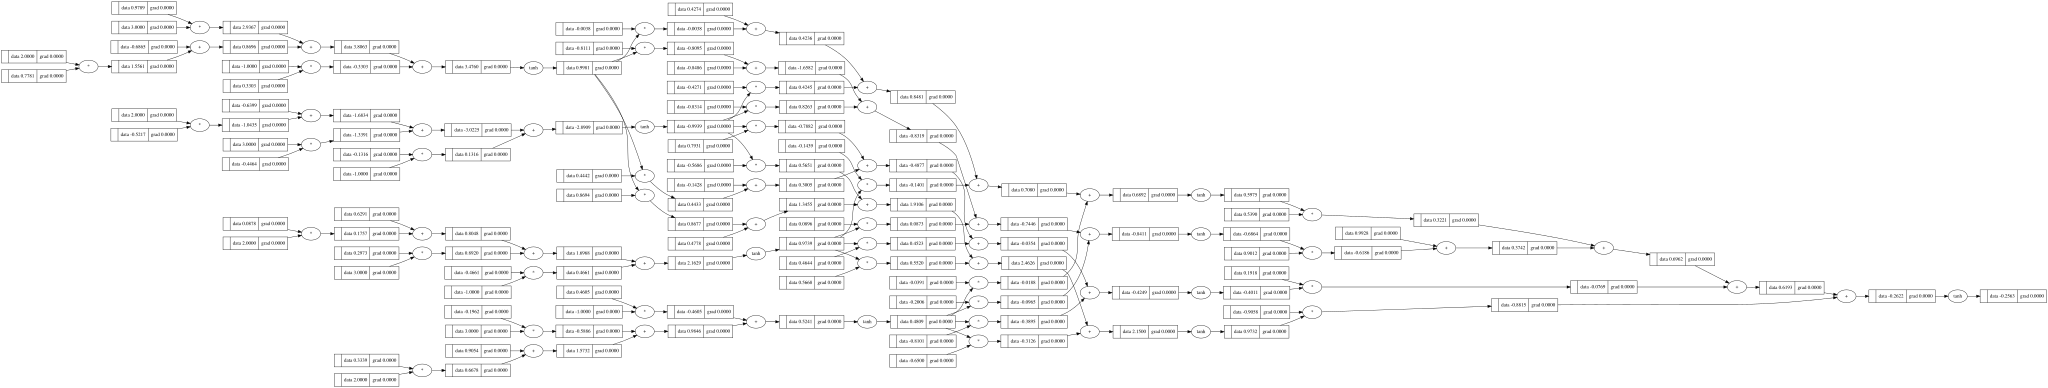

In [23]:
draw_dot(n(x))

In [24]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]

ys = [1.0, -1.0, -1.0, 1.0]

In [25]:

ypred = [n(x) for x in xs]

loss = sum(
    ((yout - ygt)**2 for ygt, yout in zip(ys, ypred)),
    Value(0.0)
)

loss

Value(data = 4.182666902369655)

In [26]:

ypred = [n(x) for x in xs]

loss = sum(
    ((yout - ygt)**2 for ygt, yout in zip(ys, ypred)),
    Value(0.0)
)

loss

Value(data = 4.182666902369655)

In [27]:
loss.backward()

In [28]:
n.layers[0].neurons[0].w[0].grad

-1.1194523103868907

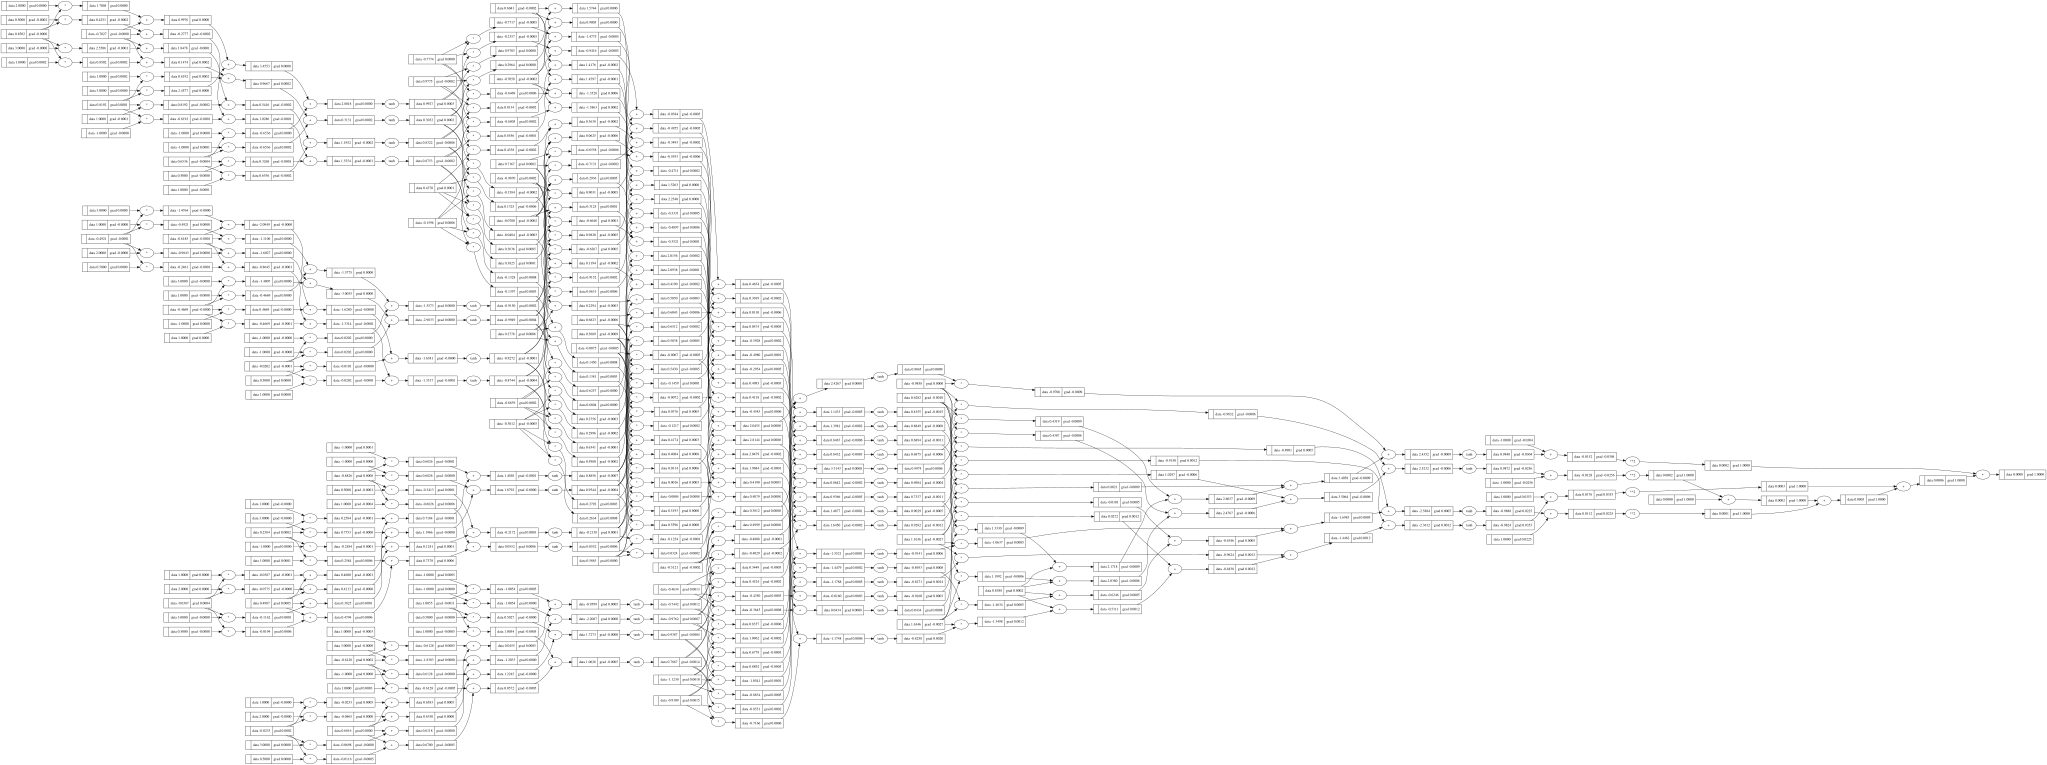

In [67]:
draw_dot(loss)

In [30]:
for p in n.parameters():
  p.data -= 0.01 * p.grad

In [65]:
for k in range(100):

    # Forward pass
    ypred = [n(x) for x in xs]

    # Calculate loss
    loss = sum(
        ((yout - ygt)**2 for ygt, yout in zip(ys, ypred)),
        Value(0.0)
    )

    # Reset gradients
    for p in n.parameters():
        p.grad = 0.0

    # Backpropagation
    loss.backward()

    # Gradient descent
    for p in n.parameters():
        p.data -= 0.01 * p.grad

    print(k, loss.data)

0 0.000858748397911764
1 0.0008584707834182964
2 0.0008581933441285738
3 0.0008579160798783317
4 0.0008576389905035002
5 0.0008573620758402312
6 0.00085708533572488
7 0.0008568087699939769
8 0.0008565323784842943
9 0.0008562561610327803
10 0.0008559801174765943
11 0.0008557042476530923
12 0.0008554285513998461
13 0.0008551530285546097
14 0.0008548776789553604
15 0.0008546025024402502
16 0.0008543274988476515
17 0.0008540526680161305
18 0.0008537780097844506
19 0.0008535035239915802
20 0.00085322921047668
21 0.0008529550690791291
22 0.0008526810996384771
23 0.0008524073019944777
24 0.000852133675987105
25 0.0008518602214565073
26 0.0008515869382430326
27 0.0008513138261872439
28 0.000851040885129881
29 0.0008507681149118968
30 0.000850495515374421
31 0.0008502230863587992
32 0.0008499508277065611
33 0.0008496787392594309
34 0.0008494068208593276
35 0.0008491350723483735
36 0.0008488634935688824
37 0.0008485920843633499
38 0.0008483208445744944
39 0.0008480497740451904
40 0.0008477788726

In [66]:
ypred

[Value(data = 0.9872171021363731),
 Value(data = -0.9887713992078287),
 Value(data = -0.9823690443861608),
 Value(data = 0.9847765014163896)]